# L1.3 - adnotacje w zbiorach detekcyjnych

W detekcji obiektów etykietą nie jest klasa całego obrazu ani maska, tylko **lista ramek** (*bounding box*): gdzie jest obiekt i jakiej jest klasy. Ramkę można zapisać na kilka sposobów i w kilku układach współrzędnych - pomyłka między nimi to najczęstszy błąd przy przygotowaniu danych do detektora.

Plan:
1. Format YOLO: kafel `.jpg` + plik `.txt` (zbiór DIOR-R)
2. Ramka a kafel: co dzieje się z adnotacją przy cięciu sceny
3. Scena z georeferencją: przejście piksel ↔ układ współrzędnych (zbiór FAIR1M), zapis do GeoJSON

Dane w `dane/detekcja/` pochodzą z publicznych zbiorów DIOR-R i FAIR1M.

In [2]:
import json
import xml.etree.ElementTree as ET
import numpy as np
import cv2
import matplotlib.pyplot as plt
import rasterio
from rasterio.warp import transform as przelicz_uklad
from PIL import Image
from pathlib import Path

DIOR = Path("dane/detekcja/dior")
FAIR = Path("dane/detekcja/fair1m")

## 1. Format YOLO

Każdy obraz ma plik tekstowy **o tej samej nazwie**: `images/00008.jpg` ↔ `labels/00008.txt`. Jeden wiersz to jeden obiekt:

```
klasa   cx   cy   w   h
```

- `klasa` - numer klasy (od 0); nazwy są w osobnym pliku, w kolejności numerów,
- `cx`, `cy` - **środek** ramki,
- `w`, `h` - szerokość i wysokość ramki,
- wszystkie cztery wartości są **znormalizowane**: podzielone przez szerokość (`cx`, `w`) lub wysokość (`cy`, `h`) obrazu, więc należą do przedziału 0–1.

Dzięki normalizacji etykieta pozostaje poprawna po przeskalowaniu obrazu.

Początek układu to lewy górny róg obrazu; oś x w prawo, oś y **w dół**.

In [3]:
NAZWY = (DIOR / "classes.txt").read_text().split()
print(len(NAZWY), "klas:", NAZWY)

print("\nlabels/00008.txt:")
print((DIOR / "labels" / "00008.txt").read_text())

20 klas: ['airplane', 'airport', 'baseballfield', 'basketballcourt', 'bridge', 'chimney', 'dam', 'Expressway-Service-area', 'Expressway-toll-station', 'golffield', 'groundtrackfield', 'harbor', 'overpass', 'ship', 'stadium', 'storagetank', 'tenniscourt', 'trainstation', 'vehicle', 'windmill']

labels/00008.txt:
0 0.108125 0.238750 0.166250 0.175000
0 0.280000 0.242500 0.130000 0.125000
0 0.501875 0.050000 0.071250 0.080000
0 0.095625 0.640625 0.126250 0.121250
0 0.251250 0.632500 0.135000 0.122500
0 0.548125 0.637500 0.133750 0.112500
0 0.315000 0.866250 0.130000 0.115000
18 0.548125 0.545625 0.086250 0.028750
18 0.041875 0.862500 0.038750 0.040000
18 0.540625 0.971875 0.041250 0.043750
18 0.238750 0.989375 0.030000 0.021250



**Zadanie 1.** Uzupełnij funkcję przeliczającą ramkę z formatu YOLO na piksele: lewy górny róg `(x1, y1)` i prawy dolny `(x2, y2)`.

Podpowiedź: środek w pikselach to `cx * W`, a lewa krawędź leży pół szerokości ramki na lewo od środka.

In [4]:
def yolo_na_piksele(cx, cy, w, h, W, H):
    # (cx, cy, w, h) znormalizowane -> (x1, y1, x2, y2) w pikselach obrazu o rozmiarze W x H
    x1 = (cx - w / 2) * W
    y1 = (cy - h / 2) * H
    x2 = (cx + w / 2) * W
    y2 = (cy + h / 2) * H
    return x1, y1, x2, y2

# test: ramka na środku obrazu 800x800, zajmująca połowę szerokości i ćwierć wysokości
print(yolo_na_piksele(0.5, 0.5, 0.5, 0.25, 800, 800), "<- oczekiwane: (200.0, 300.0, 600.0, 500.0)")

(200.0, 300.0, 600.0, 500.0) <- oczekiwane: (200.0, 300.0, 600.0, 500.0)


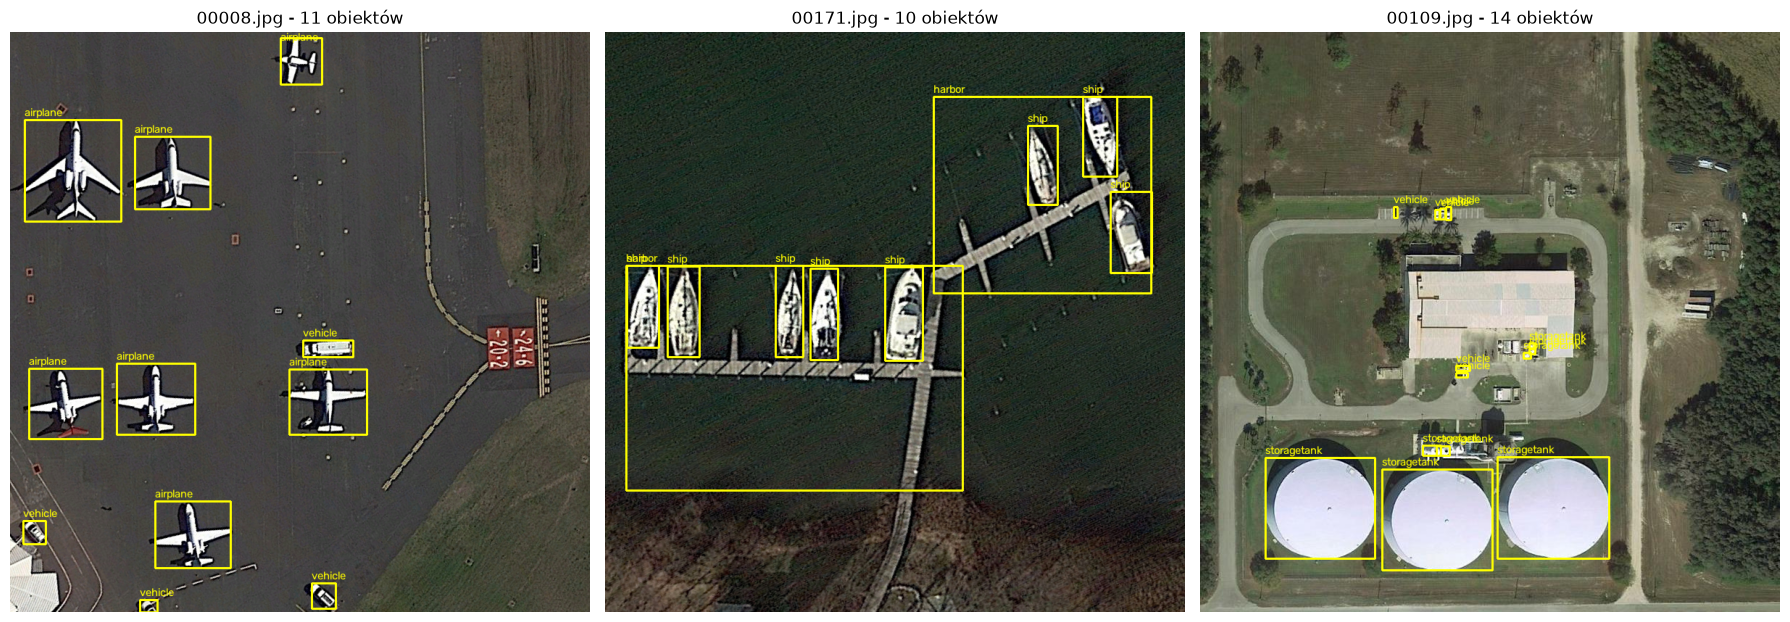

In [5]:
def wczytaj_yolo(sciezka_txt, W, H):
    # Zwraca listę ramek (klasa, x1, y1, x2, y2) w pikselach.
    ramki = []
    for wiersz in Path(sciezka_txt).read_text().splitlines():
        klasa, cx, cy, w, h = wiersz.split()
        ramki.append((int(klasa), *yolo_na_piksele(float(cx), float(cy), float(w), float(h), W, H)))
    return ramki


def rysuj_ramki(obraz, ramki, nazwy, kolor=(255, 255, 0)):
    # Rysuje ramki (klasa, x1, y1, x2, y2) z podpisem klasy; zwraca kopię obrazu.
    wynik = obraz.copy()
    for klasa, x1, y1, x2, y2 in ramki:
        x1, y1, x2, y2 = (int(round(v)) for v in (x1, y1, x2, y2))
        cv2.rectangle(wynik, (x1, y1), (x2, y2), kolor, 2)
        cv2.putText(wynik, nazwy[klasa], (x1, max(y1 - 5, 12)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, kolor, 1, cv2.LINE_AA)
    return wynik


fig, axes = plt.subplots(1, 3, figsize=(18, 6.3))
for ax, nazwa in zip(axes, ["00008", "00171", "00109"]):
    obraz = np.array(Image.open(DIOR / "images" / f"{nazwa}.jpg").convert("RGB"))
    H, W = obraz.shape[:2]
    ramki = wczytaj_yolo(DIOR / "labels" / f"{nazwa}.txt", W, H)
    ax.imshow(rysuj_ramki(obraz, ramki, NAZWY)); ax.set_title(f"{nazwa}.jpg - {len(ramki)} obiektów"); ax.axis("off")
plt.tight_layout(); plt.show()

Jeśli ramki nie leżą na obiektach, wróć do zadania 1. **Narysowanie adnotacji na obrazie to podstawowa kontrola każdego zbioru detekcyjnego** - przed treningiem zawsze oglądamy kilkanaście losowych przykładów.

**Zadanie 2.** Operacja odwrotna: z ramki w pikselach utwórz wiersz w formacie YOLO. Tak zapisuje się własne adnotacje i tak przelicza się ramki po cięciu sceny na kafle.

In [6]:
def piksele_na_yolo(x1, y1, x2, y2, W, H):
    # (x1, y1, x2, y2) w pikselach -> (cx, cy, w, h) znormalizowane
    cx = (x1 + x2) / 2 / W
    cy = (y1 + y2) / 2 / H
    w = (x2 - x1) / W
    h = (y2 - y1) / H
    return cx, cy, w, h

# kontrola: przeliczenie tam i z powrotem musi dać wartości wyjściowe
wyjsciowe = (0.108125, 0.238750, 0.166250, 0.175000)
po_powrocie = piksele_na_yolo(*yolo_na_piksele(*wyjsciowe, 800, 800), 800, 800)
print("zgodne:", np.allclose(wyjsciowe, po_powrocie))

# wiersz etykiety dla samolotu (klasa 0) w ramce x: 100-180, y: 300-360
cx, cy, w, h = piksele_na_yolo(100, 300, 180, 360, 800, 800)
print(f"0 {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}")

zgodne: True
0 0.175000 0.412500 0.100000 0.075000


### Ramki obrócone (OBB)

Ramka pozioma słabo opisuje obiekty długie i ustawione ukośnie - statek przy nabrzeżu zajmuje niewielką część swojej ramki, a ramki sąsiednich statków nakładają się. W zobrazowaniach lotniczych i satelitarnych stosuje się dlatego **ramki obrócone** (*oriented bounding box*). W wariancie YOLO-OBB wiersz zawiera klasę i cztery narożniki, również znormalizowane:

```
klasa   x1 y1   x2 y2   x3 y3   x4 y4
```

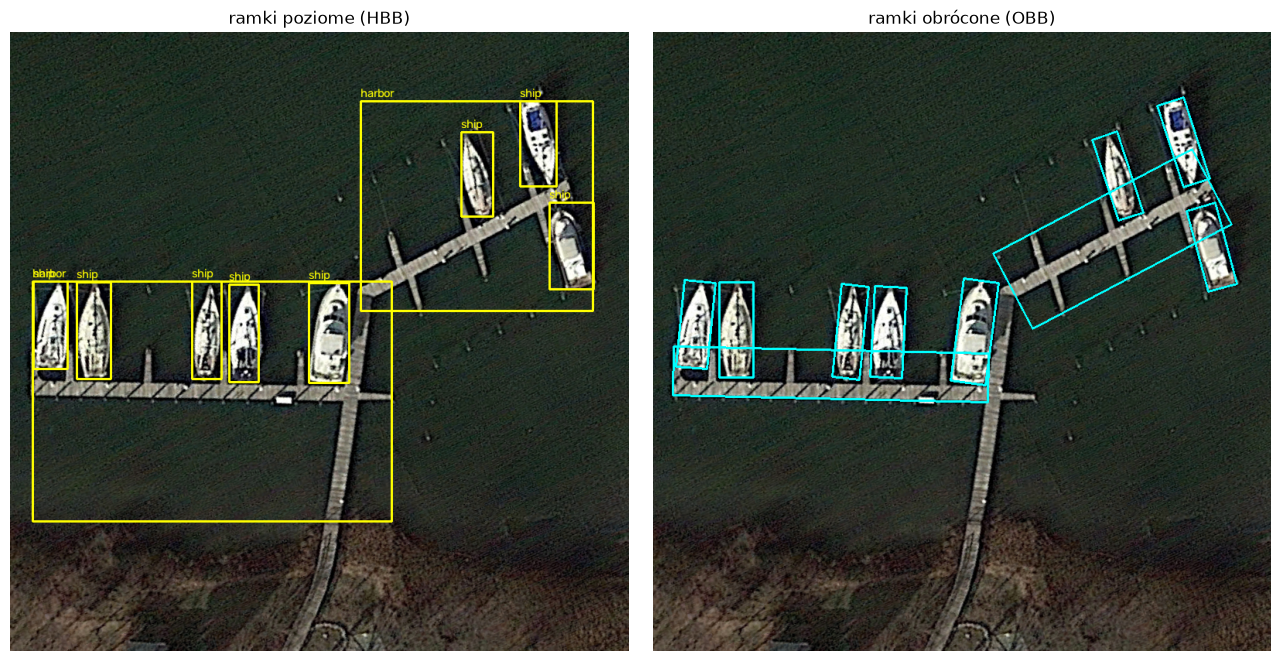

In [7]:
obraz = np.array(Image.open(DIOR / "images" / "00171.jpg").convert("RGB"))
H, W = obraz.shape[:2]

z_obb = obraz.copy()
for wiersz in (DIOR / "labels_obb" / "00171.txt").read_text().splitlines():
    wartosci = wiersz.split()
    narozniki = np.array(wartosci[1:], dtype=float).reshape(4, 2) * [W, H]      # denormalizacja
    cv2.polylines(z_obb, [narozniki.round().astype(np.int32)], isClosed=True, color=(0, 255, 255), thickness=2)

z_hbb = rysuj_ramki(obraz, wczytaj_yolo(DIOR / "labels" / "00171.txt", W, H), NAZWY)
fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))
axes[0].imshow(z_hbb); axes[0].set_title("ramki poziome (HBB)"); axes[0].axis("off")
axes[1].imshow(z_obb); axes[1].set_title("ramki obrócone (OBB)"); axes[1].axis("off")
plt.tight_layout(); plt.show()

## 2. Ramka a kafel

Adnotacje dużej sceny są zapisane w pikselach **sceny**. Po pocięciu na kafle (L1.2) każdy kafel potrzebuje własnego pliku etykiet, w pikselach **kafla**. Kafel zaczyna się w punkcie `(x0, y0)` sceny, więc:

```
x_w_kaflu = x_w_scenie - x0          y_w_kaflu = y_w_scenie - y0
```

W drugą stronę (detekcja z kafla → pozycja w scenie) dodajemy `x0`, `y0`. Po to w L1.2 zapisywaliśmy `indeks.csv`.

Ramkę wystającą poza kafel przycinamy do jego granic. Jeśli w kaflu zostaje tylko skrawek obiektu, taką ramkę lepiej pominąć - uczyłaby sieć rozpoznawać fragmenty.

Warship      w kaflu widać  53% ramki
Warship      w kaflu widać  59% ramki
Warship      w kaflu widać  94% ramki
Warship      w kaflu widać  97% ramki


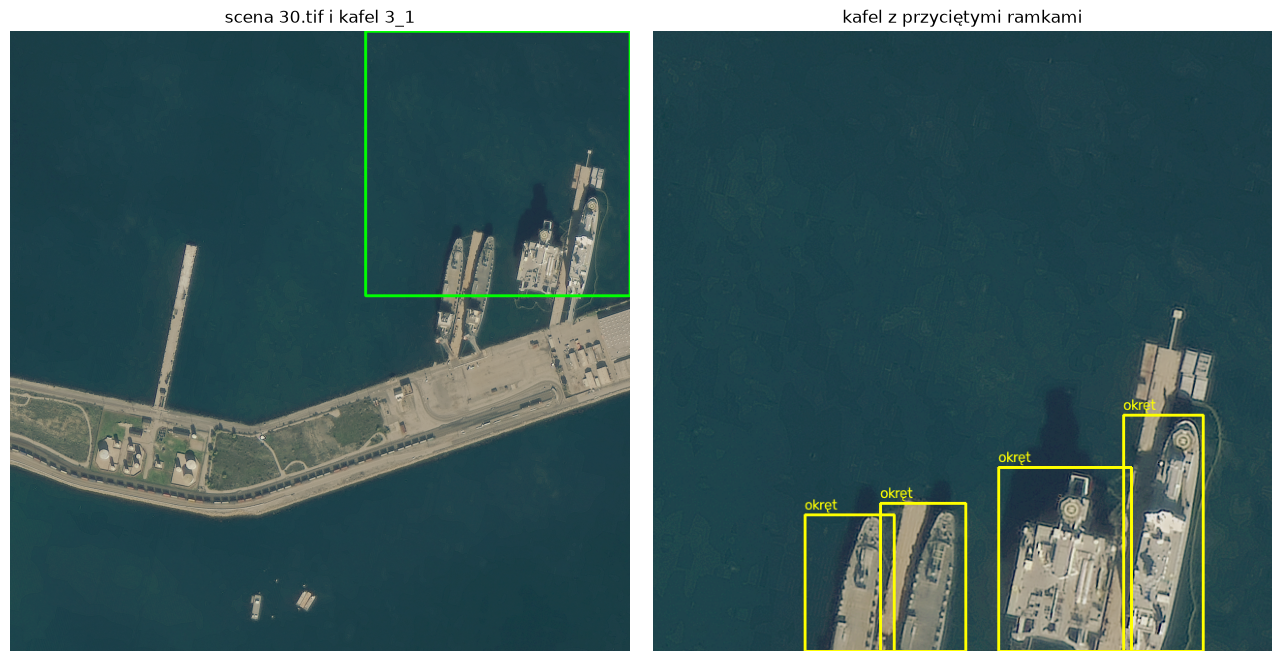

In [8]:
def wczytaj_fair1m(sciezka_xml):
    # Adnotacje FAIR1M: lista (nazwa_klasy, narożniki 4x2 w pikselach sceny).
    obiekty = []
    for ob in ET.parse(sciezka_xml).getroot().iter("object"):
        nazwa = ob.find("possibleresult/name").text
        punkty = [[float(v) for v in p.text.split(",")] for p in ob.iter("point")][:4]
        obiekty.append((nazwa, np.array(punkty)))
    return obiekty


def ramka_do_kafla(narozniki, x0, y0, tile_size):
    # Ramka pozioma obiektu w pikselach kafla, przycięta do kafla, oraz część obiektu widoczna w kaflu.
    x1, y1 = narozniki.min(axis=0) - [x0, y0]
    x2, y2 = narozniki.max(axis=0) - [x0, y0]
    pole = (x2 - x1) * (y2 - y1)
    x1p, y1p, x2p, y2p = np.clip([x1, y1, x2, y2], 0, tile_size)
    widoczne = (x2p - x1p) * (y2p - y1p) / pole
    return (x1p, y1p, x2p, y2p), widoczne


with rasterio.open(FAIR / "30.tif") as src:
    scena = np.transpose(src.read(), (1, 2, 0))
obiekty = wczytaj_fair1m(FAIR / "30.xml")

TILE, X0, Y0 = 640, 860, 0            # kafel 3_1 siatki o pokryciu 100 px
kafel = scena[Y0:Y0 + TILE, X0:X0 + TILE]

ramki_kafla = []
for nazwa, narozniki in obiekty:
    ramka, widoczne = ramka_do_kafla(narozniki, X0, Y0, TILE)
    if widoczne > 0:
        print(f"{nazwa:12s} w kaflu widać {widoczne:4.0%} ramki")
        ramki_kafla.append((0, *ramka))

plan = scena.copy()
cv2.rectangle(plan, (X0, Y0), (X0 + TILE, Y0 + TILE), (0, 255, 0), 6)
fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))
axes[0].imshow(plan); axes[0].set_title("scena 30.tif i kafel 3_1"); axes[0].axis("off")
axes[1].imshow(rysuj_ramki(kafel, ramki_kafla, ["okręt"])); axes[1].set_title("kafel z przyciętymi ramkami"); axes[1].axis("off")
plt.tight_layout(); plt.show()

Okręty mają ok. 250 px długości, a pokrycie kafli tylko 100 px, więc granica kafla przecina dwa z nich mniej więcej w połowie i żaden sąsiedni kafel nie zawiera ich w całości. **Pokrycie dobieramy do rozmiaru największych obiektów, które chcemy wykrywać** (albo zmniejszamy rozdzielczość sceny przed cięciem).

## 3. Scena z georeferencją

Detekcja „statek w pikselu (1285, 548)” jest bezużyteczna, dopóki nie wiemy, gdzie to jest na Ziemi. Raster z georeferencją (GeoTIFF) przechowuje dwie informacje:

- **CRS** - układ współrzędnych (np. EPSG:32611 = UTM strefa 11N, jednostka: metr; EPSG:4326 = długość i szerokość geograficzna, jednostka: stopień),
- **transformację afiniczną** - sześć liczb wiążących piksel `(kolumna, wiersz)` ze współrzędnymi `(x, y)` w tym układzie.

Dla typowego rastra bez obrotu:

```
x = x_lewego_górnego_rogu + rozmiar_piksela * kolumna
y = y_lewego_górnego_rogu - rozmiar_piksela * wiersz        (minus: wiersze rosną w dół, y na północ)
```

In [9]:
src = rasterio.open(FAIR / "30.tif")
T = src.transform

print("CRS:            ", src.crs)
print("rozmiar piksela:", src.res, "m")
print("zasięg:         ", src.bounds)
print("transformacja:\n", T)

CRS:             EPSG:32611
rozmiar piksela: (0.81, 0.81) m
zasięg:          BoundingBox(left=385461.18, bottom=3733785.72, right=386676.18, top=3735000.72)
transformacja:
 | 0.81, 0.00, 385461.18|
| 0.00,-0.81, 3735000.72|
| 0.00, 0.00, 1.00|


Obiekt transformacji działa jak funkcja. Mnożenie przez `T` przelicza piksel na współrzędne, a przez odwrotność `~T` współrzędne na piksel:

```python
x, y = T * (kolumna, wiersz)          # piksel  -> CRS
kolumna, wiersz = ~T * (x, y)         # CRS     -> piksel
```

Uwaga na kolejność: w tablicy numpy indeksujemy `[wiersz, kolumna]`, a transformacja przyjmuje `(kolumna, wiersz)`, czyli `(x, y)`.

In [10]:
x, y = T * (0, 0)
print("lewy górny róg sceny:    ", (x, y))
x, y = T * (1500, 1500)
print("prawy dolny róg sceny:   ", (x, y))

x, y = T * (1285.5, 548)
print("piksel (1285.5, 548) ->  ", (round(x, 2), round(y, 2)))
print("i z powrotem ->          ", ~T * (x, y))

# to samo "ręcznie", ze wzoru
print("ze wzoru:                ", (T.c + T.a * 1285.5, T.f + T.e * 548))

lewy górny róg sceny:     (385461.18, 3735000.72)
prawy dolny róg sceny:    (386676.18, 3733785.72)
piksel (1285.5, 548) ->   (386502.43, 3734556.84)
i z powrotem ->           (1285.5, 548.0)
ze wzoru:                 (386502.435, 3734556.8400000003)


**Zadanie 3.** Uzupełnij funkcję, która przelicza narożniki ramki (tablica N×2 z kolumnami `x_piksel`, `y_piksel`) na współrzędne w układzie sceny.

In [11]:
def piksele_na_crs(narozniki, T):
    # narożniki (N, 2) w pikselach -> (N, 2) we współrzędnych układu sceny
    wynik = []
    for kolumna, wiersz in narozniki:
        x, y = T * (kolumna, wiersz)
        wynik.append((x, y))
    return np.array(wynik)

nazwa, narozniki = obiekty[0]
print(nazwa, "- narożniki w pikselach:\n", narozniki)
print("narożniki w EPSG:32611 [m]:\n", piksele_na_crs(narozniki, T).round(2))

Warship - narożniki w pikselach:
 [[1064.  499.]
 [1017.  754.]
 [1062.  763.]
 [1109.  507.]]
narożniki w EPSG:32611 [m]:
 [[ 386323.02 3734596.53]
 [ 386284.95 3734389.98]
 [ 386321.4  3734382.69]
 [ 386359.47 3734590.05]]


Układ UTM jest metryczny, więc z narożników od razu dostajemy **wymiary obiektów w metrach**.

0: Warship      długość  210.8 m, szerokość  37.0 m
1: Warship      długość  207.5 m, szerokość  34.5 m
2: Warship      długość  207.1 m, szerokość  36.8 m
3: Warship      długość  144.3 m, szerokość  82.1 m
4: other-ship   długość   52.5 m, szerokość  14.8 m


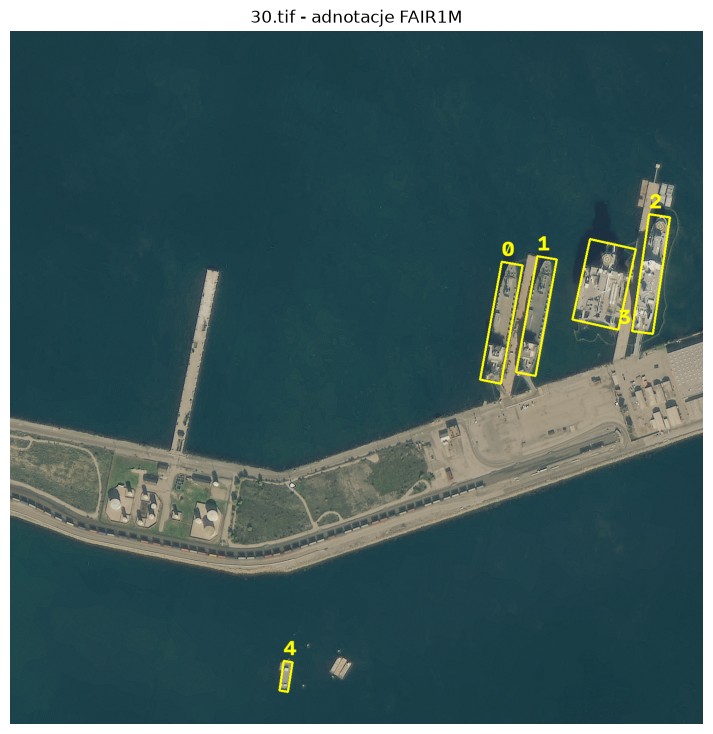

In [12]:
plan = scena.copy()
for i, (nazwa, narozniki) in enumerate(obiekty):
    w_crs = piksele_na_crs(narozniki, T)
    boki = np.linalg.norm(w_crs - np.roll(w_crs, -1, axis=0), axis=1)        # długości czterech boków [m]
    print(f"{i}: {nazwa:12s} długość {boki.max():6.1f} m, szerokość {boki.min():5.1f} m")
    cv2.polylines(plan, [narozniki.astype(np.int32)], True, (255, 255, 0), 3)
    cv2.putText(plan, str(i), tuple(narozniki[0].astype(int) - [0, 12]), cv2.FONT_HERSHEY_SIMPLEX, 1.5, (255, 255, 0), 3)

plt.figure(figsize=(9, 9)); plt.imshow(plan); plt.axis("off"); plt.title("30.tif - adnotacje FAIR1M"); plt.show()

**Zadanie 4.** Operator przekazał współrzędne celu w układzie EPSG:32611: `x = 386502.4`, `y = 3734556.8`. W którym pikselu sceny leży ten punkt i do którego obiektu należy?

In [13]:
cel_x, cel_y = 386502.4, 3734556.8

kolumna, wiersz = ~T * (cel_x, cel_y)
print(f"piksel: kolumna {kolumna:.1f}, wiersz {wiersz:.1f}")

for i, (nazwa, narozniki) in enumerate(obiekty):
    w_srodku = cv2.pointPolygonTest(narozniki.astype(np.float32), (float(kolumna), float(wiersz)), False) >= 0
    if w_srodku:
        print(f"punkt leży w ramce obiektu {i}: {nazwa}")

piksel: kolumna 1285.5, wiersz 548.0
punkt leży w ramce obiektu 3: Warship


### Zapis do GeoJSON

Żeby adnotacje lub wyniki detekcji otworzyć w QGIS, zapisujemy je jako wektor. Najprostszy format to **GeoJSON** - zwykły plik tekstowy. Standard wymaga współrzędnych w EPSG:4326 w kolejności **długość, szerokość**, więc narożniki przeliczamy z UTM funkcją `rasterio.warp.transform`.

In [14]:
obiekty_geo = []
for nazwa, narozniki in obiekty:
    w_crs = piksele_na_crs(narozniki, T)
    lon, lat = przelicz_uklad(src.crs, "EPSG:4326", w_crs[:, 0], w_crs[:, 1])       # UTM -> długość, szerokość
    pierscien = [[round(a, 7), round(b, 7)] for a, b in zip(lon, lat)]
    pierscien.append(pierscien[0])                                                 # poligon musi być zamknięty
    obiekty_geo.append({"type": "Feature",
                        "properties": {"klasa": nazwa},
                        "geometry": {"type": "Polygon", "coordinates": [pierscien]}})

geojson = {"type": "FeatureCollection", "features": obiekty_geo}
Path("adnotacje_30.geojson").write_text(json.dumps(geojson, indent=1), encoding="utf-8")

print("zapisano adnotacje_30.geojson, obiektów:", len(obiekty_geo))
print(json.dumps(obiekty_geo[0], indent=1))

zapisano adnotacje_30.geojson, obiektów: 5
{
 "type": "Feature",
 "properties": {
  "klasa": "Warship"
 },
 "geometry": {
  "type": "Polygon",
  "coordinates": [
   [
    [
     -118.2272788,
     33.7453381
    ],
    [
     -118.2276631,
     33.7434715
    ],
    [
     -118.2272688,
     33.7434097
    ],
    [
     -118.2268845,
     33.7452835
    ],
    [
     -118.2272788,
     33.7453381
    ]
   ]
  ]
 }
}


Otwórz w QGIS `dane/detekcja/fair1m/30.tif` i `adnotacje_30.geojson` - ramki powinny leżeć na okrętach.

### Zadanie dodatkowe

Scena `0.tif` ma układ EPSG:4326, czyli rozmiar piksela w stopniach.

1. Wypisz jej CRS, transformację i rozmiar piksela.
2. Przelicz narożniki największego statku na długość i szerokość geograficzną.
3. Dlaczego długości statku w metrach nie da się policzyć bezpośrednio z tych współrzędnych tak, jak w scenie `30.tif`? Co trzeba zrobić najpierw?

In [15]:
with rasterio.open(FAIR / "0.tif") as src0:
    T0 = src0.transform
    print("CRS:", src0.crs, "| rozmiar piksela:", src0.res, "stopnia")
    obiekty0 = wczytaj_fair1m(FAIR / "0.xml")
    nazwa, narozniki = max(obiekty0, key=lambda o: np.ptp(o[1], axis=0).max())
    stopnie = piksele_na_crs(narozniki, T0)
    print(nazwa, "\n", stopnie.round(6))

    # stopnie -> metry: przeliczenie do układu metrycznego (UTM 11N)
    x, y = przelicz_uklad(src0.crs, "EPSG:32611", stopnie[:, 0], stopnie[:, 1])
    metry = np.column_stack([x, y])
    boki = np.linalg.norm(metry - np.roll(metry, -1, axis=0), axis=1)
    print(f"długość {boki.max():.1f} m, szerokość {boki.min():.1f} m")

CRS: EPSG:4326 | rozmiar piksela: (5.36441802978516e-06, 5.36441802978516e-06) stopnia
Liquid Cargo Ship 
 [[-118.170152   33.73499 ]
 [-118.168977   33.736975]
 [-118.169385   33.737217]
 [-118.170555   33.735226]]
długość 245.9 m, szerokość 45.5 m


**Odpowiedź** W EPSG:4326 jednostką jest stopień, a stopień długości geograficznej ma inną długość w metrach niż stopień szerokości (na szerokości 34° ok. 92 km wobec 111 km). Odległość euklidesowa policzona w stopniach nie ma sensu fizycznego. Najpierw trzeba przeliczyć współrzędne do układu metrycznego (np. właściwej strefy UTM) albo użyć odległości geodezyjnej.

## Podsumowanie

| Układ | Jednostka | Gdzie występuje |
| --- | --- | --- |
| znormalizowany (YOLO) | ułamek szerokości i wysokości obrazu, 0–1 | pliki etykiet `.txt` |
| piksele kafla | piksel, początek w rogu kafla | wejście i wyjście sieci |
| piksele sceny | piksel, początek w rogu sceny | adnotacje dużych scen; `piksel_sceny = piksel_kafla + (x0, y0)` |
| układ współrzędnych (CRS) | metr lub stopień | GIS, raport z detekcji; `x, y = T * (kolumna, wiersz)` |

Detekcja przechodzi tę drogę od góry do dołu: sieć zwraca ramkę w kaflu, dodajemy pozycję kafla, a transformacja sceny daje współrzędne na Ziemi.